# Hull-White one-factor model

$$
dr(t) = (\theta(t) - a\, r(t))\,dt + \sigma\, dW(t), \qquad r(t) = x(t) + \alpha(t), \quad dx = -a x\,dt + \sigma dW,
$$
with $\alpha(t) = f(0,t) + \frac{\sigma^2}{2a^2}(1 - e^{-at})^2$, so that the model reprices the initial curve.
Implementation: `hull_white_1F.py`. This notebook checks the model and shows the effect of its parameters.

In [1]:
import os, sys
sys.path.append(os.path.abspath(".."))                         # Projets : Fixed_Income_Models package
sys.path.append(os.path.abspath(os.path.join("..", "Produits")))  # rate_products.py, rates_market.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rates_market import eur_curve, illustrative_cap_vols
from rate_products import CapFloor, Swaption
from Fixed_Income_Models import HullWhite, RatePricer
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
curve = eur_curve()
hw = HullWhite(curve, a=0.03, sigma=0.0085)

## 1. Fit to the initial curve

The exact simulation of $(x, \int x)$ gives the bank account discount factor $D(0,t)$ without discretisation
bias: $\mathbb{E}[D(0,t)] = P(0,t)$, and $\mathbb{E}[D(0,t) P(t,T)] = P(0,T)$ (martingale property).

In [2]:
times = np.array([0.5, 1, 2, 3, 5, 7, 10])
X, D = hw.simulate(times, 400_000, seed=1)
table = pd.DataFrame({"P(0,t) curve": curve.discount(times), "E[D(0,t)] MC": D.mean(axis=1),
                      "error (bp of price)": 1e4 * (D.mean(axis=1) - curve.discount(times)),
                      "MC std error (bp)": 1e4 * D.std(axis=1) / np.sqrt(D.shape[1])}, index=pd.Index(times, name="t"))
table["E[D(0,t) P(t,10)] - P(0,10) (bp)"] = [1e4 * (np.mean(D[k] * hw.bond_price(t, 10.0, X[k])) - curve.discount(10.0)) for k, t in enumerate(times)]
table

,"P(0,t) curve","E[D(0,t)] MC",error (bp of price),MC std error (bp),"E[D(0,t) P(t,10)] - P(0,10) (bp)"
t,,,,,
0.5,0.987528,0.987528,-5.76469e-05,0.0268869,-0.0250928
1,0.976969,0.976969,-0.000331165,0.0748537,-0.0542741
2,0.956189,0.956188,-0.00319969,0.204847,-0.184356
3,0.934447,0.934446,-0.0148713,0.363458,-0.287183
5,0.891366,0.891358,-0.0786877,0.729639,-0.397218
7,0.849676,0.849658,-0.177571,1.12892,-0.330896
10,0.790769,0.790731,-0.37741,1.74335,-0.37741


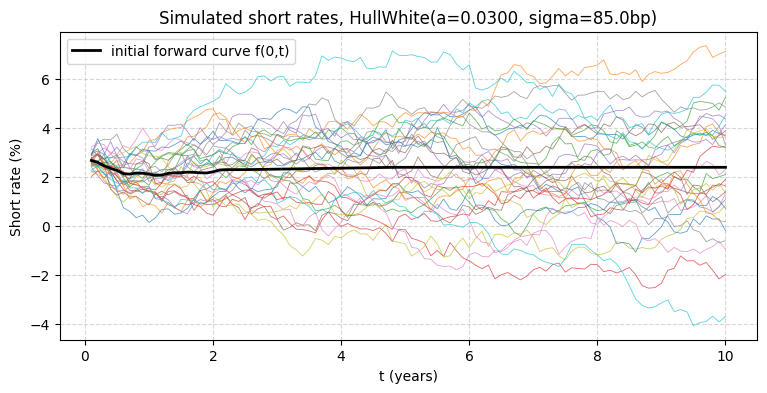

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
t = np.linspace(0, 10, 101)
X_paths, _ = hw.simulate(t[1:], 2_000, seed=2)
alpha = curve.instantaneous_forward(t[1:]) + hw.sigma**2 / (2 * hw.a**2) * (1 - np.exp(-hw.a * t[1:]))**2
ax.plot(t[1:], 100 * (X_paths[:, :30] + alpha[:, None]), linewidth=0.6, alpha=0.7)
ax.plot(t[1:], 100 * curve.instantaneous_forward(t[1:]), color="black", linewidth=2, label="initial forward curve f(0,t)")
ax.set_xlabel("t (years)"); ax.set_ylabel("Short rate (%)"); ax.set_title(f"Simulated short rates, {hw}")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.show()

## 2. Effect of the parameters on the caplet volatilities

Hull-White implied normal volatility of at-the-money caplets as a function of the fixing date. $\sigma$ sets the
level; $a > 0$ makes the volatility decrease with the fixing date (mean reversion damps long-dated rates).

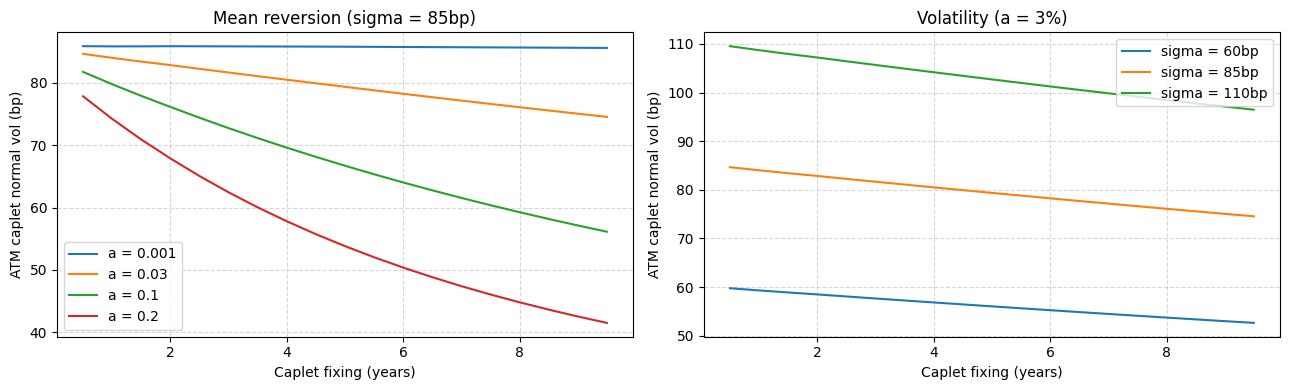

In [4]:
pricer = RatePricer(curve, illustrative_cap_vols())
fixings = np.arange(0.5, 9.6, 0.5)
def caplet_vol(model, t):
    c = CapFloor(t + 0.5, 0.0, start=t, skip_first=False)
    c = c.with_strike(pricer.par_rate(c.swap()))
    return 1e4 * pricer.implied_cap_vol(c, model.price(c))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for a in [0.001, 0.03, 0.10, 0.20]:
    axes[0].plot(fixings, [caplet_vol(HullWhite(curve, a, 0.0085), t) for t in fixings], label=f"a = {a:g}")
for s in [0.006, 0.0085, 0.011]:
    axes[1].plot(fixings, [caplet_vol(HullWhite(curve, 0.03, s), t) for t in fixings], label=f"sigma = {1e4 * s:g}bp")
for ax, title in zip(axes, ["Mean reversion (sigma = 85bp)", "Volatility (a = 3%)"]):
    ax.set_xlabel("Caplet fixing (years)"); ax.set_ylabel("ATM caplet normal vol (bp)"); ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.tight_layout(); plt.show()

## 3. Limitations

Constant $(a, \sigma)$: the caplet volatility term structure can only be flat or decreasing, which cannot fit a
humped cap volatility curve; a piecewise constant $\sigma(t)$ is the standard extension. One factor: all the rates
are perfectly correlated. Gaussian rates: negative rates are possible (consistent with the Bachelier market model).